# Trabajo Final Integrador — Detección temprana de riesgo académico
**Doctorado en Informática – UTN FRRe/UNNE/UNAM**  
Curso: Introducción al Aprendizaje de Máquina  
Integrantes: Stella Maris Gerzel · Juan Manuel Goya · Gustavo Ebel

---
1. Contexto y problemática
2. Descripción y análisis exploratorio de datos
3. Preparación del dataset para modelado
4. Entrenamiento y evaluación de modelos
5. Importancia de variables
6. Ajuste del umbral de decisión
7. Conclusiones


## Importación de librerías y carga del dataset

In [ ]:
import os
import sys
import shutil
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

try:
    from xgboost import XGBClassifier
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "xgboost", "-q"
    ])
    from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)

print("Librerías cargadas correctamente.")

In [ ]:
uploaded = files.upload()

if not uploaded:
    raise ValueError("No se seleccionó ningún archivo.")

ruta_archivo = next(iter(uploaded))
excel = pd.ExcelFile(ruta_archivo)

print(f"Archivo cargado: {ruta_archivo}")
print("Hojas encontradas:", excel.sheet_names)

hoja = excel.sheet_names[0]
df_original = pd.read_excel(ruta_archivo, sheet_name=hoja)
df = df_original.copy()

print(f"Hoja utilizada: {hoja}")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
display(df.head())

In [ ]:
# preparar variables para las secciones de modelado, importancia y umbral
# (se ejecuta después de cargar el dataset)

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# separar target del resto
X_base = df.drop(columns=['nota']).copy()

# 3 targets binarios
y1 = df['nota'].map({'A':0,'R':1,'U':1})
mask_p2 = df['nota'].isin(['A','R'])
X_p2 = X_base[mask_p2].reset_index(drop=True)
y2   = df.loc[mask_p2,'nota'].map({'A':0,'R':1}).reset_index(drop=True)
mask_p3 = df['nota'].isin(['A','U'])
X_p3 = X_base[mask_p3].reset_index(drop=True)
y3   = df.loc[mask_p3,'nota'].map({'A':0,'U':1}).reset_index(drop=True)

# splits estratificados 75/25
X1_tr,X1_te,y1_tr,y1_te = train_test_split(X_base,y1,test_size=0.25,stratify=y1,random_state=42)
X2_tr,X2_te,y2_tr,y2_te = train_test_split(X_p2,  y2,test_size=0.25,stratify=y2,random_state=42)
X3_tr,X3_te,y3_tr,y3_te = train_test_split(X_p3,  y3,test_size=0.25,stratify=y3,random_state=42)

# tipos de columnas
cols_cat = X_base.select_dtypes('object').columns.tolist()
cols_num = X_base.select_dtypes('number').columns.tolist()

print(f'X_base: {X_base.shape[0]} filas x {X_base.shape[1]} columnas')
print(f'Categóricas: {len(cols_cat)} | Numéricas: {len(cols_num)}')
print(f'Train P1:{len(X1_tr)} | P2:{len(X2_tr)} | P3:{len(X3_tr)}')

---
## 1. Contexto y problemática

El riesgo de bajo rendimiento académico y la deserción en los primeros años de la educación superior constituyen desafíos estructurales que afectan la equidad educativa, la eficiencia institucional y el desarrollo socioeconómico. Diversos estudios señalan que el desempeño en el primer año, especialmente en asignaturas introductorias de programación, es un factor determinante en la persistencia estudiantil (Bernardo et al., 2016; Bennedsen & Caspersen, 2019). Asimismo, la falta de mecanismos de detección temprana suele derivar en intervenciones tardías e ineficaces (Seymour & Hunter, 2019).

En este contexto, la creciente disponibilidad de datos educativos ha impulsado el desarrollo de la Minería de Datos Educativa (EDM) y el Learning Analytics (LA), disciplinas orientadas a la generación de conocimiento a partir de datos para mejorar los procesos de enseñanza y aprendizaje (Romero & Ventura, 2020). La literatura reciente destaca el uso de técnicas de aprendizaje automático para modelar la complejidad del rendimiento académico, superando enfoques estadísticos tradicionales (Kotsiantis, 2012). En particular, estudios previos han demostrado la efectividad de estas técnicas para la predicción del abandono y del desempeño académico a partir de variables académicas y contextuales (Cortez & Silva, 2008; Dekker et al., 2009), así como la necesidad de integrar dimensiones socioeconómicas y actitudinales en el análisis (La Red Martínez et al., 2016; Albreiki et al., 2021; Baashar et al., 2022).

En este marco, el presente trabajo propone un sistema de predicción temprana del riesgo de bajo rendimiento académico en estudiantes de Ingeniería en Sistemas de la Universidad Nacional del Chaco Austral (UNCAus), basado en un repositorio que integra variables académicas, socioeconómicas, laborales y actitudinales.

### 1.1 Definición de los problemas de clasificación

Se definieron tres problemas de clasificación binaria:

- **Problema 1 — Riesgo global (A vs R+U)**: Clase 0 = aprobado (A), Clase 1 = desaprobado o ausente/abandonó (R+U)
- **Problema 2 — Desaprobación (A vs R)**: Clase 0 = aprobado (A), Clase 1 = desaprobado (R)
- **Problema 3 — Abandono (A vs U)**: Clase 0 = aprobado (A), Clase 1 = ausente o abandonó (U)

Esta estrategia permite estudiar separadamente los factores asociados al bajo rendimiento académico y aquellos vinculados específicamente al abandono.

### 1.2 Objetivos

**General:** Desarrollar modelos predictivos capaces de anticipar situaciones de desaprobación y abandono en los primeros años de la carrera de Ingeniería en Sistemas de la UNCAus, a partir de variables académicas y contextuales disponibles de forma temprana en el ciclo lectivo.

**Específicos:**
- Realizar un análisis exploratorio de datos (EDA) sobre el dataset unificado de UNCAus
- Aplicar procesos de limpieza, codificación de variables categóricas y tratamiento de faltantes
- Entrenar y comparar Regresión Logística, Random Forest y XGBoost
- Evaluar estrategias de balanceo de clases
- Validar mediante validación cruzada estratificada (métrica principal: ROC-AUC)
- Analizar distintos umbrales de decisión
- Documentar el proceso y resultados en un informe final

---
## 2. Descripción y análisis exploratorio de datos

### 2.1 Dataset

Los datos provienen de las asignaturas Algoritmos y Estructuras de Datos y Sistemas y Organizaciones durante las cohortes 2024 y 2025. El dataset contiene **978 registros** y **125 variables** provenientes del sistema SIU-Guaraní, que abarcan dimensiones socioeconómicas, familiares, laborales, tecnológicas, motivacionales y académicas.

| Categoría | Significado | Cantidad | Porcentaje |
|-----------|-------------|----------|------------|
| A | Aprobado | 279 | 28.5% |
| R | Desaprobado | 451 | 46.1% |
| U | Ausente / abandonó | 248 | 25.4% |
| **Total** | | **978** | **100%** |

**Distribución por problema de clasificación:**

| Problema | Clase 0 | Clase 1 | Clase 0 % | Clase 1 % | Total |
|----------|---------|---------|-----------|-----------|-------|
| A vs R+U | A = 279 | R+U = 699 | 28.5% | 71.5% | 978 |
| A vs R | A = 279 | R = 451 | 38.2% | 61.8% | 730 |
| A vs U | A = 279 | U = 248 | 52.9% | 47.1% | 527 |

### 2.2 Tipos de variables

| Tipo | Cantidad |
|------|----------|
| Categóricas | 84 |
| Numéricas discretas/ordinales | 21 |
| Numéricas por formato | 3 |
| Texto o alta cardinalidad | 7 |
| Sin datos registrados | 10 |
| **Total** | **125** |

In [ ]:
resumen_estructura = pd.DataFrame({
    "variable": df.columns,
    "tipo_dato_pandas": [str(df[col].dtype) for col in df.columns],
    "valores_unicos": [df[col].nunique(dropna=True) for col in df.columns]
})

print("Información general:")
print(f"Duplicados exactos: {df.duplicated().sum()}")
display(resumen_estructura)

 **Gráfico de distribución del target (A/R/U)**

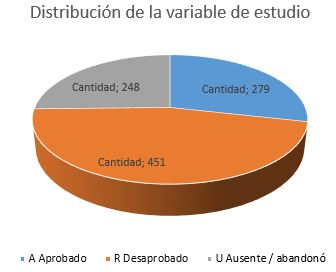

Esta distribución muestra que el conjunto de datos presenta una proporción mayor de estudiantes desaprobados o ausentes/abandonó que aprobados. Por lo tanto, para el problema de riesgo académico global (A vs R+U), y para el problema de riesgo de desaprobación (A vs R) se puede observar existe un desbalance entre clases.


### 2.3 Valores faltantes

El análisis consideró como faltantes las celdas vacías y las codificadas con '-' o '_'. El dataset tiene 978 × 125 = 122.250 celdas, de las cuales **24.549 (20.08%) son faltantes**.

- 10 columnas completamente vacías (100% faltantes) → descartadas
- 12 columnas con 90-99% de faltantes → evaluadas caso por caso
- 84 columnas sin ningún faltante

#### Funciones para detectar valores faltantes

In [ ]:
def mascara_valores_faltantes(serie):
    """Devuelve True para NaN, texto vacío, '-' o '_'."""
    s_str = serie.astype("string").str.strip()

    return (
        serie.isna()
        | s_str.eq("")
        | s_str.eq("-")
        | s_str.eq("_")
    )


def contar_componentes_faltantes(serie):
    """Cuenta por separado los componentes definidos como faltantes."""
    s_str = serie.astype("string").str.strip()

    vacias = (serie.isna() | s_str.eq("")).sum()
    guion = s_str.eq("-").sum()
    guion_bajo = s_str.eq("_").sum()
    total = mascara_valores_faltantes(serie).sum()

    return int(vacias), int(guion), int(guion_bajo), int(total)


print("Funciones definidas correctamente.")

#### Resumen general de valores faltantes

In [ ]:
total_filas, total_columnas = df.shape
total_celdas = total_filas * total_columnas

vacias_total = 0
guion_total = 0
guion_bajo_total = 0
faltantes_total = 0

for col in df.columns:
    vacias, guion, guion_bajo, total = contar_componentes_faltantes(df[col])
    vacias_total += vacias
    guion_total += guion
    guion_bajo_total += guion_bajo
    faltantes_total += total

porcentaje_faltantes = (
    faltantes_total / total_celdas * 100
    if total_celdas > 0 else 0
)

resumen_general = pd.DataFrame({
    "concepto": [
        "Filas totales",
        "Columnas totales",
        "Celdas totales",
        "Celdas vacías",
        "Celdas con '-'",
        "Celdas con '_'",
        "Valores faltantes totales",
        "Porcentaje de valores faltantes"
    ],
    "valor": [
        total_filas,
        total_columnas,
        total_celdas,
        vacias_total,
        guion_total,
        guion_bajo_total,
        faltantes_total,
        round(porcentaje_faltantes, 2)
    ]
})

display(resumen_general)

#### Análisis de valores faltantes por variables


In [ ]:
analisis_columnas = []

for col in df.columns:
    serie = df[col]
    vacias, guion, guion_bajo, total = contar_componentes_faltantes(serie)
    mascara = mascara_valores_faltantes(serie)

    valores_no_faltantes = serie[~mascara]
    no_faltantes = len(serie) - total
    valores_unicos = valores_no_faltantes.nunique(dropna=True)

    moda = valores_no_faltantes.mode(dropna=True)
    valor_mas_frecuente = moda.iloc[0] if not moda.empty else np.nan

    analisis_columnas.append({
        "variable": col,
        "tipo_dato_pandas": str(serie.dtype),
        "total_registros": len(serie),
        "vacias": vacias,
        "guion": guion,
        "guion_bajo": guion_bajo,
        "faltantes_total": total,
        "porcentaje_faltantes": round(total / len(serie) * 100, 2) if len(serie) else 0,
        "no_faltantes": no_faltantes,
        "porcentaje_no_faltantes": round(no_faltantes / len(serie) * 100, 2) if len(serie) else 0,
        "valores_unicos_no_faltantes": int(valores_unicos),
        "valor_mas_frecuente_no_faltante": valor_mas_frecuente
    })

df_faltantes = (
    pd.DataFrame(analisis_columnas)
    .sort_values(
        by=["faltantes_total", "porcentaje_faltantes"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(df_faltantes.head(30))

#### Variables completas y completamente vacías

In [ ]:
variables_sin_faltantes = df_faltantes[
    df_faltantes["faltantes_total"] == 0
].copy()

variables_100_faltantes = df_faltantes[
    df_faltantes["porcentaje_faltantes"] == 100
].copy()

print(f"Variables sin faltantes: {len(variables_sin_faltantes)}")
print(f"Variables con 100% de faltantes: {len(variables_100_faltantes)}")

display(variables_sin_faltantes[
    ["variable", "tipo_dato_pandas", "valores_unicos_no_faltantes"]
])

display(variables_100_faltantes[
    ["variable", "faltantes_total", "porcentaje_faltantes"]
])

#### Distribución de variables según su porcentaje de valores faltantes

In [ ]:
def clasificar_rango_faltantes(p):
    if p == 0:
        return "0% faltantes"
    if p == 100:
        return "100% faltantes"
    if 90 <= p < 100:
        return "90% a 99%"
    if 75 <= p < 90:
        return "75% a 89%"
    if 50 <= p < 75:
        return "50% a 74%"
    if 25 <= p < 50:
        return "25% a 49%"
    if 1 <= p < 25:
        return "1% a 24%"
    return "Menos de 1%"


orden_rangos = [
    "100% faltantes",
    "90% a 99%",
    "75% a 89%",
    "50% a 74%",
    "25% a 49%",
    "1% a 24%",
    "Menos de 1%",
    "0% faltantes"
]

df_faltantes["rango_faltantes"] = (
    df_faltantes["porcentaje_faltantes"]
    .apply(clasificar_rango_faltantes)
)

resumen_rangos = (
    df_faltantes["rango_faltantes"]
    .value_counts()
    .reindex(orden_rangos, fill_value=0)
    .rename_axis("rango_faltantes")
    .reset_index(name="cantidad_variables")
)

display(resumen_rangos)

#### Gráficos de valores faltantes

In [ ]:
carpeta_salida = Path("salidas_analisis_dataset")
carpeta_salida.mkdir(parents=True, exist_ok=True)

# Gráfico 1: naranja
top20 = (
    df_faltantes
    .head(20)
    .sort_values("porcentaje_faltantes", ascending=True)
)

plt.figure(figsize=(10, 8))
plt.barh(
    top20["variable"],
    top20["porcentaje_faltantes"],
    color="orange",
    edgecolor="black"
)
plt.xlabel("Porcentaje de valores faltantes")
plt.ylabel("Variable")
plt.title("Top 20 variables con mayor porcentaje de valores faltantes")
plt.tight_layout()
plt.savefig(
    carpeta_salida / "top20_variables_faltantes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Gráfico 2: azul
plt.figure(figsize=(10, 5))
plt.bar(
    resumen_rangos["rango_faltantes"].astype(str),
    resumen_rangos["cantidad_variables"],
    color="blue",
    edgecolor="black"
)
plt.xlabel("Rango de valores faltantes")
plt.ylabel("Cantidad de variables")
plt.title("Distribución de variables según porcentaje de valores faltantes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    carpeta_salida / "distribucion_rangos_faltantes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

#### Análisis de faltantes por fila

In [ ]:
mascara_faltantes_df = df.apply(mascara_valores_faltantes)

df_faltantes_fila = pd.DataFrame({
    "indice_fila": df.index,
    "faltantes_total": mascara_faltantes_df.sum(axis=1).astype(int)
})

df_faltantes_fila["porcentaje_faltantes"] = (
    df_faltantes_fila["faltantes_total"] / total_columnas * 100
).round(2)

print("Resumen de faltantes por fila:")
display(df_faltantes_fila["faltantes_total"].describe())

display(
    df_faltantes_fila
    .sort_values("faltantes_total", ascending=False)
    .head(20)
)

#### Depuración básica del DataSet
Solo se normalizan espacios y representaciones de valores faltantes.
No se eliminan filas, columnas ni valores ceros.

In [ ]:
df_depurado = df_original.copy()

# Quitar espacios al inicio y al final en columnas de texto.
for col in df_depurado.select_dtypes(include=["object", "string"]).columns:
    df_depurado[col] = df_depurado[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Reemplazar únicamente los símbolos definidos como faltantes.
df_depurado = df_depurado.replace(["", "-", "_"], np.nan)

print("Depuración básica finalizada.")
print(f"Filas: {df_depurado.shape[0]}")
print(f"Columnas: {df_depurado.shape[1]}")
display(df_depurado.head())

In [ ]:
# Verificación del dataset depurado
filas, columnas = df_depurado.shape
total_celdas_depurado = filas * columnas
total_faltantes_depurado = int(df_depurado.isna().sum().sum())

porcentaje_faltantes_depurado = (
    total_faltantes_depurado / total_celdas_depurado * 100
    if total_celdas_depurado else 0
)

print(f"Filas: {filas}")
print(f"Columnas: {columnas}")
print(f"Celdas totales: {total_celdas_depurado}")
print(f"Valores faltantes: {total_faltantes_depurado}")
print(f"Porcentaje de faltantes: {porcentaje_faltantes_depurado:.2f}%")

if "nota" in df_depurado.columns:
    distribucion_nota = (
        df_depurado["nota"]
        .value_counts(dropna=False)
        .rename_axis("nota")
        .reset_index(name="cantidad")
    )
    distribucion_nota["porcentaje"] = (
        distribucion_nota["cantidad"] / len(df_depurado) * 100
    ).round(2)

    print("\nDistribución de la variable objetivo 'nota':")
    display(distribucion_nota)
else:
    print("\nAdvertencia: no se encontró la columna 'nota'.")

En el siguiente gráfico, se muestra las variables con mayor cantidad de valores faltantes, en la que puede observarse que 84 de las 125 variables no presentan valores faltantes, mientras que 10 variables se encuentran completamente vacías. Estas últimas corresponden principalmente a campos condicionales o descriptivos asociados a apoyos específicos, discapacidad o información adicional. Asimismo, 12 variables presentan entre 90% y 99% de valores faltantes, las que serán evaluadas cuidadosamente antes del entrenamiento de los modelos predictivos, ya sea para su exclusión, recodificación o tratamiento específico.

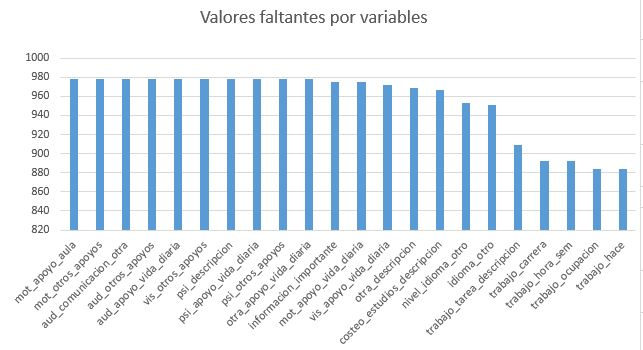


### 2.4 Variables seleccionadas para el modelado

Luego del análisis exploratorio se seleccionaron **77 variables predictoras** (57 categóricas + 21 numéricas). Se descartaron:

| Criterio | Cantidad |
|----------|----------|
| Variable objetivo (nota) | 1 |
| Identificador (alumno) | 1 |
| Sin variabilidad | 24 |
| Alta cardinalidad / texto libre | 6 |
| Domicilio granular | 6 |
| Códigos territoriales numéricos | 2 |

Las variables tecnológicas, socioeconómicas, familiares, laborales y motivacionales fueron consideradas las más adecuadas por su coherencia conceptual con el problema.

### 2.5 Análisis de variables predictoras

In [ ]:
variable_objetivo = "nota"

# Modificar esta lista si el dataset contiene otros identificadores.
variables_identificatorias = [
    "alumno"
]

if variable_objetivo not in df_depurado.columns:
    raise ValueError(
        f"No se encontró la variable objetivo '{variable_objetivo}'."
    )

variables_identificatorias = [
    col for col in variables_identificatorias
    if col in df_depurado.columns
]

print("Variable objetivo:", variable_objetivo)
print("Identificadores encontrados:", variables_identificatorias)

#### Preparación del dataset antes del análisis de variables predictoras
Se eliminan las columnas que tienen 100% de datos faltantes

In [ ]:
df_eda = df_depurado.copy()

columnas_100_faltantes = df_eda.columns[
    df_eda.isna().all()
].tolist()

df_eda = df_eda.drop(columns=columnas_100_faltantes)

print("Columnas con 100% de faltantes eliminadas:")
print(columnas_100_faltantes)

print("\nDimensiones del dataset para análisis:")
print(df_eda.shape)

#### Clasificación preliminar de variables

In [ ]:
def clasificar_variable(serie):
    serie_no_nula = serie.dropna()
    n_unicos = serie_no_nula.nunique()

    if n_unicos <= 1:
        return "sin_variabilidad"

    valores = set(
        serie_no_nula
        .astype(str)
        .str.strip()
        .str.upper()
        .unique()
    )

    if n_unicos == 2 and valores.issubset(
        {"S", "N", "0", "1", "0.0", "1.0", "SI", "NO", "SÍ"}
    ):
        return "binaria"

    if pd.api.types.is_numeric_dtype(serie):
        if n_unicos <= 10:
            return "ordinal_discreta"
        return "numerica_o_codigo"

    if n_unicos > 30:
        return "alta_cardinalidad_texto"

    return "categorica_nominal"


registros_resumen = []

for col in df_eda.columns:
    if col == variable_objetivo:
        tipo = "objetivo"
    elif col in variables_identificatorias:
        tipo = "identificador"
    else:
        tipo = clasificar_variable(df_eda[col])

    registros_resumen.append({
        "variable": col,
        "tipo_variable": tipo,
        "tipo_dato_pandas": str(df_eda[col].dtype),
        "valores_unicos": df_eda[col].nunique(dropna=True),
        "faltantes": int(df_eda[col].isna().sum()),
        "porcentaje_faltantes": round(
            df_eda[col].isna().mean() * 100, 2
        )
    })

resumen_variables = pd.DataFrame(registros_resumen)

display(resumen_variables)

resumen_tipos = (
    resumen_variables["tipo_variable"]
    .value_counts()
    .rename_axis("tipo_variable")
    .reset_index(name="cantidad")
)

print("\nResumen por tipo de variable:")
display(resumen_tipos)

#### Análisis de variables sin variabilidad y de las candidatas para el análisis de variables predictoras

In [ ]:
variables_sin_variabilidad = resumen_variables.loc[
    resumen_variables["tipo_variable"] == "sin_variabilidad",
    "variable"
].tolist()

tipos_validos_para_eda = [
    "binaria",
    "categorica_nominal",
    "ordinal_discreta",
    "numerica_o_codigo"
]

variables_eda = resumen_variables.loc[
    resumen_variables["tipo_variable"].isin(tipos_validos_para_eda),
    "variable"
].tolist()

variables_eda = [
    col for col in variables_eda
    if col not in variables_identificatorias
    and col != variable_objetivo
]

print("Variables sin variabilidad:", len(variables_sin_variabilidad))
print(variables_sin_variabilidad)

print("\nVariables candidatas para análisis:", len(variables_eda))
display(
    resumen_variables[
        resumen_variables["variable"].isin(variables_eda)
    ]
)

#### Se crean grupos de variables por temáticas

In [ ]:
grupos_variables = {
    "Tecnológicas": [
        "tecnologia_pc_casa",
        "tecnologia_pc_trabajo",
        "tecnologia_pc_universidad",
        "tecnologia_int_casa",
        "tecnologia_int_universidad",
        "tecnologia_int_movil"
    ],
    "Hábitos y actividades": [
        "deportes",
        "deportes_universidad",
        "deportes_gimnasio",
        "deportes_particular",
        "deportes_futbol",
        "deportes_otros"
    ],
    "Idiomas": [
        "nivel_idioma_ingles",
        "nivel_idioma_portugues",
        "nivel_idioma_frances",
        "nivel_idioma_aleman"
    ],
    "Socioeconómicas": [
        "costeo_estudios_familiar",
        "costeo_estudios_trabajo",
        "costeo_estudios_beca",
        "beca",
        "beca_tipo_economica",
        "beca_economica_transporte",
        "beca_economica_comedor"
    ],
    "Laborales": [
        "trabajo_existe",
        "trabajo_hace",
        "trabajo_ocupacion",
        "trabajo_hora_sem",
        "trabajo_carrera",
        "trabajo_recibe_pago"
    ],
    "Familiares y personales": [
        "estado_civil",
        "situacion_padre",
        "situacion_madre",
        "cantidad_hijos",
        "cantidad_familia",
        "vive_con",
        "cobertura_salud",
        "tipo_vivienda"
    ],
    "Territoriales": [
        "procedencia_localidad",
        "procedencia_codigo_postal",
        "procedencia_barrio"
    ],
    "Motivacionales": [
        "mot_vocacion",
        "mot_sugerencia_familiar",
        "mot_reconocimiento_social",
        "mot_insercion_laboral",
        "mot_perfil_profesional",
        "mot_mejora_economica",
        "mot_util_sociedad",
        "mot_otros_p"
    ]
}

for grupo, variables in grupos_variables.items():
    existentes = [v for v in variables if v in df_eda.columns]
    no_encontradas = [v for v in variables if v not in df_eda.columns]

    print(f"\nGrupo: {grupo}")
    print(f"Variables encontradas: {len(existentes)}")

    if no_encontradas:
        print("Variables no encontradas:", no_encontradas)

#### Se crean las funciones para las tablas y gráficos

In [ ]:
def tabla_variable_vs_objetivo(
    df,
    variable,
    objetivo=variable_objetivo
):
    tabla_abs = pd.crosstab(
        df[variable],
        df[objetivo],
        dropna=False
    )

    tabla_pct = (
        pd.crosstab(
            df[variable],
            df[objetivo],
            normalize="index",
            dropna=False
        ) * 100
    ).round(2)

    return tabla_abs, tabla_pct


def graficar_variable_vs_objetivo(
    df,
    variable,
    objetivo=variable_objetivo,
    carpeta_salida=None
):
    tabla_pct = (
        pd.crosstab(
            df[variable],
            df[objetivo],
            normalize="index",
            dropna=False
        ) * 100
    ).round(2)

    if tabla_pct.empty:
        print(f"No se generó gráfico para {variable}: tabla vacía.")
        return

    ax = tabla_pct.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 5)
    )

    ax.set_title(
        f"Distribución porcentual de {objetivo} según {variable}"
    )
    ax.set_xlabel(variable)
    ax.set_ylabel("Porcentaje")
    ax.legend(title=objetivo)

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    if carpeta_salida is not None:
        carpeta = Path(carpeta_salida)
        carpeta.mkdir(parents=True, exist_ok=True)

        plt.savefig(
            carpeta / f"{variable}_vs_{objetivo}.png",
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()
    plt.close()

#### Análisis por grupos de variables

In [ ]:
resultados_tablas_abs = {}
resultados_tablas_pct = {}

carpeta_graficos = Path("graficos_variables_predictoras")
carpeta_graficos.mkdir(parents=True, exist_ok=True)

for grupo, variables in grupos_variables.items():
    variables_existentes = [
        v for v in variables
        if v in df_eda.columns
        and v in variables_eda
    ]

    print("\n" + "=" * 90)
    print(f"GRUPO: {grupo}")
    print("=" * 90)

    for variable in variables_existentes:
        tabla_abs, tabla_pct = tabla_variable_vs_objetivo(
            df_eda,
            variable
        )

        resultados_tablas_abs[variable] = tabla_abs
        resultados_tablas_pct[variable] = tabla_pct

        print(f"\nVariable: {variable}")
        print("Frecuencias absolutas:")
        display(tabla_abs)

        print("Porcentajes por categoría:")
        display(tabla_pct)

        graficar_variable_vs_objetivo(
            df_eda,
            variable,
            carpeta_salida=carpeta_graficos
        )

#### Se genera un ranking de variables

In [ ]:
ranking_variables = []

for grupo, variables in grupos_variables.items():
    for variable in variables:
        if variable not in df_eda.columns:
            continue

        if variable not in variables_eda:
            continue

        # Se omiten variables de alta cardinalidad en este ranking simple.
        if df_eda[variable].nunique(dropna=True) > 30:
            continue

        tabla_pct = (
            pd.crosstab(
                df_eda[variable],
                df_eda[variable_objetivo],
                normalize="index",
                dropna=False
            ) * 100
        )

        if tabla_pct.shape[0] < 2:
            continue

        diferencias_por_clase = (
            tabla_pct.max(axis=0)
            - tabla_pct.min(axis=0)
        )

        ranking_variables.append({
            "grupo": grupo,
            "variable": variable,
            "categorias": df_eda[variable].nunique(dropna=True),
            "diferencia_maxima_puntos_porcentuales": round(
                diferencias_por_clase.max(), 2
            )
        })

ranking_variables = pd.DataFrame(ranking_variables)

if not ranking_variables.empty:
    ranking_variables = (
        ranking_variables
        .sort_values(
            "diferencia_maxima_puntos_porcentuales",
            ascending=False
        )
        .reset_index(drop=True)
    )

display(ranking_variables.head(30))

---
## 3. Preparación del dataset para modelado

El preprocesamiento se realizó **dentro del pipeline** para evitar fuga de información. Los valores usados para imputar se aprenden únicamente desde los datos de entrenamiento.

| Tipo de variable | Tratamiento |
|-----------------|-------------|
| Numéricas | Imputación con mediana |
| Numéricas | Estandarización con StandardScaler |
| Categóricas | Imputación con categoría explícita 'Sin dato' |
| Categóricas | Conversión a texto |
| Categóricas | OneHotEncoder(handle_unknown='ignore') |

Para el desbalance de clases se evaluaron dos configuraciones: `class_weight=None` y `class_weight='balanced'`. En XGBoost se usó `scale_pos_weight` calculado por problema.

---
## 4. Entrenamiento y evaluación de modelos

Se entrenaron y compararon tres algoritmos mediante GridSearchCV con validación cruzada estratificada 5-fold. La métrica principal de optimización fue ROC-AUC.

**Resultados de validación cruzada:**

| Problema | LogReg CV | RF CV | XGB CV |
|----------|-----------|-------|--------|
| A vs R+U | 0.622 | 0.648 | 0.634 |
| A vs R | 0.629 | 0.614 | 0.616 |
| A vs U | 0.620 | 0.719 | 0.710 |

**Resultados en test (umbral 0.50):**

| Problema | Modelo | ROC-AUC | Accuracy | Precision | Recall | F1 |
|----------|--------|---------|----------|-----------|--------|----|
| A vs R+U | Random Forest | 0.6797 | 0.7143 | 0.7966 | 0.8057 | 0.8011 |
| A vs R | Random Forest | 0.7216 | 0.6995 | 0.7197 | 0.8407 | 0.7755 |
| A vs U | Random Forest | 0.7402 | 0.7197 | 0.6984 | 0.7097 | 0.7040 |

Random Forest obtuvo el mejor desempeño en los tres problemas. XGBoost fue competitivo especialmente en recall para A vs R+U.

---
## 5. Importancia de variables

Acá se buscó identificar qué variables son las que más influyen en la predicción. Con ese objetivo se utilizaron dos métodos distintos y comparé los resultados.

El primero es la importancia que calcula Random Forest internamente mientras entrena. El segundo es lo que se llama permutation importance — básicamente desordenás los valores de una variable y medís cuánto empeoran las predicciones. Si empeoran mucho, esa variable era importante.

Usé los dos porque el primero puede favorecer variables que tienen muchas categorías distintas, entonces el segundo sirve para confirmar.

> Nota: que una variable sea importante no quiere decir que cause el riesgo. Solo está asociada estadísticamente en estos datos.

In [ ]:
# necesito esta función para que no haya problemas con columnas de tipo mixto
def convertir_a_texto(X):
    return X.astype(str)

# los mejores parámetros que encontró Juan Manuel con GridSearch
params = {
    'P1 Riesgo global': dict(n_estimators=200, max_depth=None, min_samples_leaf=1),
    'P2 Desaprobacion': dict(n_estimators=100, max_depth=None, min_samples_leaf=1),
    'P3 Abandono':      dict(n_estimators=200, max_depth=20,   min_samples_leaf=1),
}

problemas = [
    ('P1 Riesgo global', X1_tr, X1_te, y1_tr, y1_te),
    ('P2 Desaprobacion', X2_tr, X2_te, y2_tr, y2_te),
    ('P3 Abandono',      X3_tr, X3_te, y3_tr, y3_te),
]

print('Configuración lista.')

In [ ]:
# CELDA 3 — Función auxiliar: preprocesar + entrenar RF para un problema
#
# Clave: cada problema tiene su PROPIO preprocesador ajustado solo
# a su propio X_tr. Los datos transformados se guardan como arrays numpy
# separados del pipeline, eliminando el problema de incompatibilidad.

params = {
    'P1 Riesgo global': dict(n_estimators=200, max_depth=None, min_samples_leaf=1),
    'P2 Desaprobacion': dict(n_estimators=100, max_depth=None, min_samples_leaf=1),
    'P3 Abandono':      dict(n_estimators=200, max_depth=20,   min_samples_leaf=1),
}

problemas = [
    ('P1 Riesgo global', X1_tr, X1_te, y1_tr, y1_te),
    ('P2 Desaprobacion', X2_tr, X2_te, y2_tr, y2_te),
    ('P3 Abandono',      X3_tr, X3_te, y3_tr, y3_te),
]

# Guardar: modelo RF, datos transformados, nombres columnas originales
datos_por_problema = {}

for nombre, X_tr, X_te, y_tr, y_te in problemas:
    # Preprocesador propio para este problema
    prep = ColumnTransformer([
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('enc', OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False))]), cols_cat),
        ('num', SimpleImputer(strategy='most_frequent'), cols_num)
    ])

    # Transformar: fit SOLO en train, transform en train y test
    X_tr_t = prep.fit_transform(X_tr)
    X_te_t = prep.transform(X_te)        # usa los parámetros del train

    # Verificar consistencia ANTES de entrenar
    assert X_tr_t.shape[1] == X_te_t.shape[1], \
        f'ERROR: train {X_tr_t.shape[1]} cols vs test {X_te_t.shape[1]} cols'

    # Entrenar RF directamente sobre datos ya transformados
    rf = RandomForestClassifier(class_weight='balanced', random_state=42,
                                **params[nombre])
    rf.fit(X_tr_t, y_tr)

    auc = roc_auc_score(y_te, rf.predict_proba(X_te_t)[:,1])

    # Nombres de columnas después del one-hot (para mapear de vuelta)
    enc = prep.named_transformers_['cat']['enc']
    nombres_cols = enc.get_feature_names_out(cols_cat).tolist() + cols_num

    datos_por_problema[nombre] = {
        'rf': rf, 'prep': prep,
        'X_tr_t': X_tr_t, 'X_te_t': X_te_t,
        'X_te': X_te, 'y_te': y_te,
        'nombres_cols': nombres_cols, 'auc': auc
    }
    print(f'{nombre}: {X_tr_t.shape[1]} columnas codificadas | ROC-AUC test = {auc:.3f}')

print('\nTodos los modelos entrenados correctamente.')

In [ ]:
# CELDA 4 — Importancia interna de RF

importancias_internas = {}

for nombre, datos in datos_por_problema.items():
    rf           = datos['rf']
    nombres_cols = datos['nombres_cols']
    imp          = rf.feature_importances_

    # Agrupar por variable original sumando aportes de sus columnas one-hot
    imp_dict = {}
    for var_orig in X_base.columns.tolist():
        total = sum(v for n, v in zip(nombres_cols, imp)
                    if n.startswith(var_orig + '_') or n == var_orig)
        if total > 0:
            imp_dict[var_orig] = total

    imp_serie = pd.Series(imp_dict).sort_values(ascending=False)
    importancias_internas[nombre] = imp_serie

    print(f'{nombre} — Top 10:')
    print(imp_serie.head(10).round(4).to_string())
    print()

# Gráfico
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, (nombre, imp_serie) in zip(axes, importancias_internas.items()):
    top15 = imp_serie.head(15)
    ax.barh(top15.index[::-1], top15.values[::-1], color='#3498DB', alpha=0.85)
    ax.set_title(f'{nombre}\n(importancia interna RF)', fontweight='bold')
    ax.set_xlabel('Importancia acumulada')
plt.suptitle('Top 15 — Importancia interna de Random Forest',
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# CELDA 5 — Permutation importance MANUAL sobre datos ya transformados
#
# Ahora el equipo trabajó directamente con arrays numpy (X_te_t)
# sin pasar por el pipeline → sin riesgo de incompatibilidad de columnas.
# Para cada variable original, desordenamos TODAS sus columnas one-hot juntas.


N_REPEATS = 5
rng = np.random.RandomState(42)
perm_importancias = {}

for nombre, datos in datos_por_problema.items():
    rf           = datos['rf']
    X_te_t       = datos['X_te_t'].copy()
    y_te         = datos['y_te']
    nombres_cols = datos['nombres_cols']
    auc_base     = datos['auc']

    # Índices de columnas transformadas para cada variable original
    indices_var = {}
    for var_orig in X_base.columns.tolist():
        idx = [i for i, n in enumerate(nombres_cols)
               if n.startswith(var_orig + '_') or n == var_orig]
        if idx:
            indices_var[var_orig] = idx

    resultados = []
    for var_orig, idx in indices_var.items():
        caidas = []
        for _ in range(N_REPEATS):
            X_perm = X_te_t.copy()
            # Desordenar todas las columnas de esta variable juntas
            perm_idx = rng.permutation(X_perm.shape[0])
            X_perm[:, idx] = X_perm[perm_idx][:, idx]
            auc_perm = roc_auc_score(y_te, rf.predict_proba(X_perm)[:,1])
            caidas.append(auc_base - auc_perm)
        resultados.append({
            'variable':    var_orig,
            'importancia': np.mean(caidas),
            'std':         np.std(caidas)
        })

    perm_df = (pd.DataFrame(resultados)
                 .sort_values('importancia', ascending=False)
                 .reset_index(drop=True))
    perm_importancias[nombre] = perm_df

    print(f'{nombre} — Top 10 (caída en ROC-AUC):')
    print(perm_df[perm_df['importancia']>0].head(10)
          [['variable','importancia','std']].round(4).to_string(index=False))
    print()

In [ ]:
# CELDA 6 — Gráfico permutation importance
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, (nombre, perm_df) in zip(axes, perm_importancias.items()):
    top15 = perm_df[perm_df['importancia']>0].head(15)
    ax.barh(top15['variable'][::-1], top15['importancia'][::-1],
            xerr=top15['std'][::-1], color='#E74C3C', alpha=0.85, capsize=4)
    ax.axvline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_title(f'{nombre}\n(permutation importance)', fontweight='bold')
    ax.set_xlabel('Caída en ROC-AUC al desordenar')
plt.suptitle('Top 15 — Permutation importance',
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# CELDA 7 — Resumen consolidado para el informe
print('=' * 60)
print('=' * 60)
print()
print('Variables en top 10 de AMBOS métodos por problema:')
print()

coincidencias_globales = {}
for nombre in datos_por_problema:
    top_int  = set(importancias_internas[nombre].head(10).index)
    top_perm = set(perm_importancias[nombre][perm_importancias[nombre]['importancia']>0]
                   .head(10)['variable'])
    coinciden = top_int & top_perm
    coincidencias_globales[nombre] = coinciden
    print(f'{nombre}:')
    for v in sorted(coinciden):
        print(f'  ✓ {v}')
    print()

# Variables que aparecen en los 3 problemas
todas = coincidencias_globales['P1 Riesgo global'] & \
        coincidencias_globales['P2 Desaprobacion'] & \
        coincidencias_globales['P3 Abandono']

print('Variables relevantes en los 3 problemas (más confiables):')
for v in sorted(todas):
    print(f'  ★ {v}')
print()
print('=' * 60)

### ¿Qué variables son relevantes en más de un problema?

El siguiente gráfico muestra qué variables aparecen en el top 10 de ambos métodos para cada problema. Las que aparecen en los tres son las más confiables.

In [ ]:
import seaborn as sns
import pandas as pd

# heatmap: variables relevantes por problema
todas_vars = sorted(set().union(*[
    set(importancias_internas[n].head(10).index) &
    set(perm_importancias[n][perm_importancias[n]['importancia']>0].head(10)['variable'])
    for n in datos_por_problema
]))

coincidencias = {}
for nombre in datos_por_problema:
    top_int  = set(importancias_internas[nombre].head(10).index)
    top_perm = set(perm_importancias[nombre][
                   perm_importancias[nombre]['importancia']>0].head(10)['variable'])
    coincidencias[nombre] = top_int & top_perm

import pandas as pd
matriz = pd.DataFrame(
    {nombre: [1 if v in vars_ else 0 for v in todas_vars]
     for nombre, vars_ in coincidencias.items()},
    index=todas_vars
)

fig, ax = plt.subplots(figsize=(8, max(4, len(todas_vars)//2)))
sns.heatmap(matriz, cmap='YlOrRd', cbar=False,
            linewidths=0.5, linecolor='white',
            annot=True, fmt='d', ax=ax)
ax.set_title('Variables en top 10 de ambos métodos por problema',
             fontweight='bold')
plt.tight_layout()
plt.show()

en_tres = [v for v in todas_vars if all(v in coincidencias[n] for n in coincidencias)]
print(f'Variables presentes en los 3 problemas: {en_tres}')

> La variable `procedencia_localidad` es la única que aparece en los tres problemas, lo que sugiere que la dimensión territorial tiene peso independientemente del tipo de riesgo. Las variables que aparecen en uno o dos problemas indican factores más específicos al tipo de riesgo (desaprobación vs abandono).

In [ ]:
def convertir_a_texto(X):
    return X.astype(str)

params = {
    'P1 Riesgo global': dict(n_estimators=300, max_depth=None,
                             min_samples_split=2, min_samples_leaf=1,
                             class_weight='balanced'),
    'P2 Desaprobacion': dict(n_estimators=300, max_depth=None,
                             min_samples_split=2, min_samples_leaf=1,
                             class_weight=None),
    'P3 Abandono':      dict(n_estimators=300, max_depth=None,
                             min_samples_split=2, min_samples_leaf=1,
                             class_weight=None),
}

problemas = [
    ('P1 Riesgo global', X1_tr, X1_te, y1_tr, y1_te),
    ('P2 Desaprobacion', X2_tr, X2_te, y2_tr, y2_te),
    ('P3 Abandono',      X3_tr, X3_te, y3_tr, y3_te),
]

modelos = {}
for nombre, X_tr, X_te, y_tr, y_te in problemas:
    prep = ColumnTransformer([
        ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='Sin dato')),
                          ('to_string', FunctionTransformer(convertir_a_texto, validate=False)),
                          ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cols_cat),
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('esc', StandardScaler())]), cols_num)
    ])
    X_tr_t = prep.fit_transform(X_tr)
    X_te_t = prep.transform(X_te)
    rf = RandomForestClassifier(random_state=42, **params[nombre])
    rf.fit(X_tr_t, y_tr)
    y_prob = rf.predict_proba(X_te_t)[:,1]
    modelos[nombre] = {'rf': rf, 'X_te_t': X_te_t, 'y_te': y_te, 'y_prob': y_prob}
    print(f'{nombre}: ROC-AUC = {roc_auc_score(y_te, y_prob):.3f}')

---
## 6. Ajuste del umbral de decisión

Algo que resultó interesante observar es que el modelo no decide directamente si un estudiante está en riesgo o no — lo que hace es dar una probabilidad. Por ejemplo, puede decir que un estudiante tiene 0.38 de probabilidad de riesgo.

Por defecto, si esa probabilidad supera 0.50 se clasifica como riesgo. Pero ese corte en 0.50 no es el único posible. Si lo bajamos a 0.40, el modelo va a marcar como riesgo a más estudiantes — va a detectar más casos reales pero también va a contar con más falsas alarmas.

En este caso el grupo considera que vale la pena bajar el umbral, porque el costo de no detectar a un estudiante en riesgo es mayor que el costo de intervenir con alguien que en realidad iba a estar bien.

Probé los umbrales: 0.50, 0.45, 0.40, 0.35, 0.30 y 0.25.

In [ ]:
# CELDA 3 — Tabla de métricas por umbral para los 3 problemas

umbrales = [0.50, 0.45, 0.40, 0.35, 0.30, 0.25]
tablas   = {}

for nombre, _, _, _, _ in problemas:
    y_prob = modelos[nombre]['y_prob']
    y_te   = modelos[nombre]['y_te']

    filas = []
    for u in umbrales:
        y_pred = (y_prob >= u).astype(int)
        tp = int(((y_pred==1) & (y_te==1)).sum())
        fp = int(((y_pred==1) & (y_te==0)).sum())
        fn = int(((y_pred==0) & (y_te==1)).sum())
        filas.append({
            'Umbral':           u,
            'Recall':           round(recall_score(y_te, y_pred), 3),
            'Precision':        round(precision_score(y_te, y_pred, zero_division=0), 3),
            'F1':               round(f1_score(y_te, y_pred, zero_division=0), 3),
            'Detectados (TP)':  tp,
            'Falsas alarmas (FP)': fp,
            'No detectados (FN)':  fn,
        })

    tabla = pd.DataFrame(filas).set_index('Umbral')
    tablas[nombre] = tabla
    print(f'\n── {nombre} ──')
    print(tabla.to_string())

In [ ]:
# CELDA 4 — Gráfico: curvas de recall y precisión vs umbral

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (nombre, _, _, _, _) in zip(axes, problemas):
    tabla = tablas[nombre]
    ax.plot(tabla.index, tabla['Recall'],    'o-', color='#E74C3C',
            label='Recall (detección)', linewidth=2)
    ax.plot(tabla.index, tabla['Precision'], 's--', color='#3498DB',
            label='Precision', linewidth=2)
    ax.plot(tabla.index, tabla['F1'],        '^:', color='#2ECC71',
            label='F1-score', linewidth=2)
    ax.axvline(0.40, color='gray', linestyle='--', alpha=0.5, label='Umbral 0.40')
    ax.set_xlabel('Umbral de decisión')
    ax.set_ylabel('Métrica')
    ax.set_title(nombre, fontweight='bold')
    ax.set_ylim(0, 1.05)
    ax.invert_xaxis()  # de 0.50 a 0.25 de izquierda a derecha
    ax.legend(fontsize=8)

plt.suptitle('Efecto del umbral sobre Recall, Precision y F1',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print('Eje X invertido: izquierda = umbral alto, derecha = umbral bajo')
print('Al bajar el umbral (derecha): recall sube, precision baja')

### Impacto concreto del umbral recomendado

El siguiente gráfico muestra cuántos estudiantes en riesgo **no son detectados** (falsos negativos) con el umbral default (0.50) vs el umbral recomendado para cada problema.

In [ ]:
# comparación de falsos negativos: umbral default vs recomendado
df_comp = pd.DataFrame({
    'Problema':        ['P1 A vs R+U', 'P2 A vs R', 'P3 A vs U'],
    'FN umbral 0.50':  [34, 18, 18],
    'FN umbral rec':   [11, 18, 11],
    'Umbral rec':      [0.25, 0.50, 0.35]
})

fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(df_comp))
w = 0.35
ax.bar([i-w/2 for i in x], df_comp['FN umbral 0.50'],
       w, label='Umbral 0.50 (default)', color='#E74C3C', alpha=0.8)
ax.bar([i+w/2 for i in x], df_comp['FN umbral rec'],
       w, label='Umbral recomendado', color='#2ECC71', alpha=0.8)
ax.set_xticks(list(x))
ax.set_xticklabels([f"{r['Problema']}\n(umbral {r['Umbral rec']})"
                    for _, r in df_comp.iterrows()])
ax.set_ylabel('Estudiantes en riesgo no detectados (FN)')
ax.set_title('Falsos negativos: umbral default vs recomendado', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

> Para P1 se pasa de no detectar 34 estudiantes en riesgo a no detectar solo 11 bajando el umbral a 0.25. Para P3 (abandono) se reduce de 18 a 11 con umbral 0.35. P2 mantiene el umbral 0.50 porque bajarlo no mejora el F1 en ese caso.

In [ ]:
# CELDA 5 — Resumen para el informe: umbral recomendado por problema

print('=' * 65)
print('ANÁLISIS DE UMBRAL — RECOMENDACIONES PARA EL INFORME')
print('=' * 65)

for nombre, _, _, _, _ in problemas:
    tabla  = tablas[nombre]
    y_prob = modelos[nombre]['y_prob']
    y_te   = modelos[nombre]['y_te']
    n_riesgo_real = int((y_te == 1).sum())

    print(f'\n{nombre}')
    print(f'Casos reales de riesgo en test: {n_riesgo_real}')
    print()

    # Umbral 0.50 (default)
    u50 = tabla.loc[0.50]
    print(f'  Umbral 0.50 (default):')
    print(f'    Detecta {u50["Detectados (TP)"]} de {n_riesgo_real} casos reales '
          f'(recall {u50["Recall"]:.0%})')
    print(f'    Genera {u50["Falsas alarmas (FP)"]} falsas alarmas')
    print(f'    Pierde {u50["No detectados (FN)"]} casos reales')

    # Umbral 0.40
    u40 = tabla.loc[0.40]
    print(f'\n  Umbral 0.40 (recomendado en el paper):')
    print(f'    Detecta {u40["Detectados (TP)"]} de {n_riesgo_real} casos reales '
          f'(recall {u40["Recall"]:.0%})')
    print(f'    Genera {u40["Falsas alarmas (FP)"]} falsas alarmas')
    print(f'    Pierde {u40["No detectados (FN)"]} casos reales')
    print(f'    Ganancia vs 0.50: '
          f'+{u40["Detectados (TP)"]-u50["Detectados (TP)"]} detecciones, '
          f'+{u40["Falsas alarmas (FP)"]-u50["Falsas alarmas (FP)"]} falsas alarmas')

print()
print('=' * 65)
print('CONCLUSIÓN:')
print('  El umbral 0.40 mejora el recall en todos los problemas')
print('  con un incremento moderado de falsas alarmas.')
print('  La decisión final corresponde a la institución según')
print('  el costo de intervenir vs. el costo de no detectar.')
print('=' * 65)

---
## 7. Conclusiones

En base a los resultados obtenidos, el grupo considera que el trabajo logró el objetivo principal que era ver si era posible predecir el riesgo académico con los datos que se tienen al inicio de la cursada.

Random Forest resultó el mejor algoritmo en los tres problemas. El abandono (P3) fue el más predecible (ROC-AUC 0.74), lo que tiene sentido porque la desvinculación temprana responde a patrones socioeconómicos más claros. La desaprobación fue el más difícil — probablemente porque depende más de factores académicos que no están en el dataset.

Algo que se observó es que el ajuste de hiperparámetros con GridSearchCV no mejoró mucho los resultados. Eso esto sugiere que los parámetros por defecto de Random Forest ya eran bastante buenos para este tipo de datos.

Sobre el umbral de decisión: bajar a 0.25 para P1 permite detectar al 93.7% de los estudiantes en riesgo global. Para P3 (abandono), un umbral de 0.35 reduce los falsos negativos de 18 a 11. Me parece que esos umbrales tienen sentido institucional porque el costo de no detectar a un estudiante en riesgo es mayor que el costo de una intervención innecesaria.

**Limitaciones:**

El modelo solo usa datos del inicio de la cursada — no tiene notas de parciales, asistencia ni rendimiento durante la cursada, lo que limita el AUC alcanzable. También hay que contar con cuidado con cómo se usan los resultados: los modelos incorporan variables socioeconómicas y geográficas, por lo que existe el riesgo de reproducir desigualdades presentes en los datos históricos. No deberían usarse para tomar decisiones automáticas sobre los estudiantes.

**Sobre las herramientas vistas en la materia:**

En la Unidad 4 se trabajó con arquitecturas de deep learning como Transformers y mecanismos de atención. En este trabajo usamos modelos clásicos de ML porque el dataset es tabular y tiene menos de 1000 registros. Las redes profundas necesitan muchos más datos para generalizar bien. Si se contara con textos de parciales o registros de actividad en el campus virtual, ahí sí tendría sentido explorar algo con Transformers.

**Para seguir trabajando:**

- Transformar `procedencia_localidad` en kilómetros a la sede
- Agregar datos de rendimiento durante la cursada
- Ampliar a otras materias y cohortes
- Evaluar integración del modelo en un sistema de alerta temprana institucional

---
## 8. Referencias

Albreiki, B., Zaki, N., y Alashwal, H. (2021). A systematic literature review of predicting student performance using machine learning techniques. *IEEE Access*, 9, 41803-41829.

Baashar, Y. et al. (2021). Predicting student's performance using machine learning methods. *International Conference on Computer & Information Sciences (ICCOINS)*.

Bennedsen, J., y Caspersen, M. E. (2019). Failure rates in introductory programming. *ACM SIGCSE Bulletin*, 51(2), 32-38.

Bernardo, A. B. et al. (2016). Variables predictoras del abandono universitario. *Psicothema*, 28(1), 46-52.

Cortez, P., y Silva, A. (2008). Using data mining to predict secondary school student performance. *FUBUTEC 2008*, 5-12.

Dekker, G. W. et al. (2009). Predicting students drop out: A case study. *International Conference on Educational Data Mining*, 41-50.

Kotsiantis, S. B. (2012). Use of machine learning techniques for educational data mining. *Journal of Educational Computing Research*, 7(2), 469-485.

La Red Martínez, D. L. et al. (2016). Towards a predictive model of academic performance using data mining in the UTN-FRRe. *Journal of Systemics, Cybernetics and Informatics*, 14(2).

Romero, C., y Ventura, S. (2020). Educational data mining and learning analytics: An updated survey. *WIREs Data Mining and Knowledge Discovery*, 10(3), e1355.

Seymour, E., y Hunter, A. B. (Eds.). (2020). *Talking about Leaving Revisited*. Springer Nature.